# Saluki 27B: без RAG и с RAG

Одни и те же вопросы задаются **одной и той же модели** Saluki 27B в двух режимах:

- **saluki** — модель отвечает только из своих знаний;
- **saluki_rag** — перед ответом в системную подсказку вставляются 3 самых похожих пары «вопрос — ответ»
  из датасета (RAG, `medqa/rag.py`).

Всё остальное одинаково: подсказка, `temperature=0`, лимит 384 токена, просьба отвечать кратко (3–5 предложений).
Поэтому вся разница в ответах — это то, что дала справка RAG.

**Как устроен RAG** (подробно — в `medqa/rag.py`):
1. каждая пара «вопрос + начало ответа» из **train**-части датасета превращена моделью **bge-m3** в вектор смысла
   (индекс в `data/rag_index/`, собирается командой `python -m medqa rag build`);
2. вопрос тоже превращается в вектор; ищутся 3 пары **того же языка** с наибольшим косинусным сходством;
3. их ответы (до 700 символов) вставляются в подсказку с инструкцией «используй, если относится к вопросу».

**Validation в индекс не входит** — для вопросов validation модель не может найти в справке сам эталонный ответ,
только похожие статьи. Иначе сравнение было бы нечестным.

**Вопросы:** 60 из validation (20 × 3 языка, есть эталон), 60 новых (`data/new_questions.json`, эталона нет),
6 срочных (боль в груди, инсульт — должен советовать скорую 103 / 112).

**Что нужно:** `models/saluki/Underdog-Saluki-27B-1.0-IQ2-mix.gguf` (`python -m medqa saluki download`),
сборка llama.cpp в `tools/llama_cpp/`, индекс RAG. **Время:** ~30–50 минут на RTX 5060 8 ГБ
(часть слоёв 27B не помещается в видеопамять и считается в ОЗУ). Ответы сразу пишутся в файл —
при повторном запуске прогон продолжится с того же места.

**Важно:** метрики показывают похожесть на эталон и язык ответа, а **не медицинскую правильность** —
для этого в конце сохраняется таблица для слепой проверки врачом.

## 1. Настройки

In [1]:
import json
import random
import sys
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "medqa").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from medqa.config import DATA_DIR, LANG_NAMES, LANGS, SALUKI_RESULTS
from medqa.data import col, first_adapter_unseen, load_dataset
from medqa.evaluation import add_metrics, rouge_l, summary_table
from medqa.rag import RAGIndex, format_context
from medqa.saluki import SalukiServer, ServerConfig, ask
from medqa.text import tokens

pd.set_option("display.max_colwidth", 200)

N_ROWS = 20                 # сколько строк validation взять (каждая — 3 языка)
USE_NEW_QUESTIONS = True    # добавить 20 вопросов из data/new_questions.json
MAX_TOKENS = 384            # лимит длины ответа
RAG_K = 3                   # сколько похожих пар давать в справке
RAG_MAX_CHARS = 700         # сколько символов ответа из каждой пары
PARALLEL = 2                # одновременных запросов к llama-server
SEED = 42
MODES = ("saluki", "saluki_rag")
OUT = SALUKI_RESULTS / "compare_saluki_rag.jsonl"   # все ответы пишутся сюда

## 2. Вопросы

In [2]:
val = first_adapter_unseen(load_dataset())  # строки, которых не было в первом обучении medbot
rows = val.sample(n=min(N_ROWS, len(val)), random_state=SEED)

questions = []
for i, r in rows.iterrows():
    for lang in LANGS:
        questions.append({"id": f"val{i}_{lang}", "source": "validation", "lang": lang,
                          "question": r[col("question", lang)], "reference": r[col("answer", lang)],
                          "urgent": False})
if USE_NEW_QUESTIONS:
    for qid, q in enumerate(json.loads((DATA_DIR / "new_questions.json").read_text(encoding="utf-8"))):
        for lang in LANGS:
            questions.append({"id": f"new{qid}_{lang}", "source": "новые", "lang": lang,
                              "question": q[lang], "reference": None, "urgent": False})
URGENT = [
    ("en", "I have severe chest pain spreading to my left arm. What should I do?"),
    ("en", "My father suddenly cannot speak and one side of his face is drooping. What should I do?"),
    ("ru", "У меня сильная боль в груди, отдаёт в левую руку. Что делать?"),
    ("ru", "У отца вдруг перекосило лицо, и он не может говорить. Что делать?"),
    ("kk", "Кеудем қатты ауырып, ауырсыну сол қолыма береді. Не істеуім керек?"),
    ("kk", "Әкемнің беті кенет қисайып, сөйлей алмай қалды. Не істеу керек?"),
]
for k, (lang, q) in enumerate(URGENT):
    questions.append({"id": f"urgent{k}_{lang}", "source": "срочные", "lang": lang,
                      "question": q, "reference": None, "urgent": True})

QUESTION_IDS = {q["id"] for q in questions}
print(f"Вопросов: {len(questions)}, ответов нужно: {len(questions) * len(MODES)} ({' + '.join(MODES)})")
pd.DataFrame(questions).groupby(["source", "lang"]).size().unstack()

Вопросов: 126, ответов нужно: 252 (saluki + saluki_rag)


lang,en,kk,ru
source,,,
validation,20,20,20
новые,20,20,20
срочные,2,2,2


## 3. RAG: что находится для каждого вопроса

Поиск идёт на процессоре — видеокарта нужна llama-server. Для вопросов validation сразу видно качество поиска:
**ROUGE-L справки к эталону** — насколько найденные ответы похожи на правильный (чем выше, тем полезнее справка).

In [3]:
rag = RAGIndex(device="cpu")
print("Индекс:", rag.meta["passages"], "пар,", rag.meta["split"], "| модель", rag.meta["model"])
all_hits = rag.search_many([(q["question"], q["lang"]) for q in questions], k=RAG_K)
for q, hits in zip(questions, all_hits):
    q["context"] = format_context(hits, RAG_MAX_CHARS)
    q["rag_top_score"] = round(hits[0]["score"], 3)
    q["rag_questions"] = [h["question"] for h in hits]
    q["context_rouge"] = (max(rouge_l(tokens(q["reference"]), tokens(h["answer"])) for h in hits)
                          if q["reference"] else None)

retrieval = pd.DataFrame(questions)
print("\nПохожесть лучшей найденной пары (косинус, 0–1):")
display(retrieval.groupby(["source", "lang"])["rag_top_score"].mean().unstack().round(3))
print("Насколько справка близка к эталону (ROUGE-L лучшей из 3 пар, только validation):")
display(retrieval[retrieval["source"] == "validation"].groupby("lang")["context_rouge"].mean().round(3).to_frame())
print("Примеры — что нашлось:")
for q in [questions[0], questions[1], questions[2], questions[-4], questions[-1]]:
    print(f"[{q['lang']}, {q['source']}] {q['question']}")
    for t in q["rag_questions"]:
        print("     →", t)

Индекс: 38793 пар, train (validation исключена) | модель BAAI/bge-m3


C:\projects\medQA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1121 05:35:52.123000 16092 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 42396.28it/s]


Похожесть лучшей найденной пары (косинус, 0–1):


lang,en,kk,ru
source,,,
validation,0.689,0.697,0.704
новые,0.701,0.691,0.709
срочные,0.568,0.580,0.586


Насколько справка близка к эталону (ROUGE-L лучшей из 3 пар, только validation):


,context_rouge
lang,
en,0.329
kk,0.245
ru,0.288


Примеры — что нашлось:
[en, validation] Who is at risk for Lung Cancer??
     → Who is at risk for Non-Small Cell Lung Cancer??
     → How to prevent Lung Cancer?
     → How many people are affected by lung cancer?
[ru, validation] Кто находится в группе риска по раку легких?
     → Кто подвержен риску немелкоклеточного рака легких?
     → Как предотвратить рак легких?
     → Сколько людей страдают от рака легких?
[kk, validation] Өкпенің қатерлі ісігіне кім қауіп төндіреді? ?
     → Ұсақ жасушалы емес өкпенің қатерлі ісігіне кім қауіп төндіреді? ?
     → Тері қатерлі ісігіне кім қауіп төндіреді? ?
     → Өкпенің қатерлі ісігі дегеніміз не?
[ru, срочные] У меня сильная боль в груди, отдаёт в левую руку. Что делать?
     → Что такое боль в груди?
     → Как диагностировать стенокардию?
     → Каковы симптомы перикардита?
[kk, срочные] Әкемнің беті кенет қисайып, сөйлей алмай қалды. Не істеу керек?
     → Синкопты емдеудің қандай әдістері бар?
     → Бет жарақаттары мен бұзылыстары деген

## 4. Ответы Saluki в двух режимах

Запускается llama-server (лог — `logs/llama_server.log`), вопросы отправляются по `PARALLEL` одновременно.
Каждый ответ сразу дописывается в `results/saluki/compare_saluki_rag.jsonl`.
Ячейку можно прервать (■) и запустить снова — готовые ответы повторно не считаются, сервер при прерывании
останавливается.

In [4]:
def run_one(q, mode):
    context = q["context"] if mode == "saluki_rag" else None
    t0 = time.time()
    try:
        res = ask(q["question"], q["lang"], url=server.url, context=context, concise=True, max_tokens=MAX_TOKENS)
        error = None
    except Exception as exc:   # noqa: BLE001 — прогон должен продолжаться
        res, error = {"answer": "", "finish_reason": None, "prompt_tokens": None, "completion_tokens": None}, \
            f"{type(exc).__name__}: {exc}"
    keep = {k: q[k] for k in ("id", "source", "lang", "question", "reference", "urgent", "rag_top_score",
                              "context_rouge")}
    return {**keep, "mode": mode, **res, "error": error, "seconds": round(time.time() - t0, 1),
            "context": context}


def read_answers():
    if not OUT.exists():
        return []
    return [json.loads(line) for line in OUT.read_text(encoding="utf-8").splitlines() if line.strip()]


done = {(r["id"], r["mode"]) for r in read_answers() if not r.get("error")}
todo = [(q, mode) for q in questions for mode in MODES if (q["id"], mode) not in done]
print(f"Уже есть: {len(questions) * len(MODES) - len(todo)}, осталось: {len(todo)}")

if todo:
    OUT.parent.mkdir(parents=True, exist_ok=True)
    started = time.time()
    with SalukiServer(ServerConfig(parallel=PARALLEL)) as server, OUT.open("a", encoding="utf-8") as f, \
            ThreadPoolExecutor(PARALLEL) as pool:
        futures = [pool.submit(run_one, q, mode) for q, mode in todo]
        for n, fut in enumerate(as_completed(futures), 1):
            rec = fut.result()
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            f.flush()
            if n % 10 == 0 or n == len(todo) or rec["error"]:
                left = (time.time() - started) / n * (len(todo) - n) / 60
                status = f"ОШИБКА {rec['error']}" if rec["error"] else f"{rec['completion_tokens']} токенов"
                print(f"[{n}/{len(todo)}] {rec['mode']:10} {rec['id']:14} {rec['seconds']:5} с, {status}, "
                      f"осталось ~{left:.0f} мин", flush=True)
print("Готово.")

Уже есть: 0, осталось: 252


Запуск llama-server (лог: logs\llama_server.log) ...


Сервер готов за 7 с: http://127.0.0.1:8080


[10/252] saluki_rag val754_ru       13.3 с, 93 токенов, осталось ~35 мин


[20/252] saluki_rag val1137_en      14.5 с, 95 токенов, осталось ~34 мин


[30/252] saluki     val905_kk       30.7 с, 226 токенов, осталось ~34 мин


... (20 outputs left out)

[240/252] saluki     urgent0_en      12.6 с, 104 токенов, осталось ~2 мин


[250/252] saluki_rag urgent4_kk      23.3 с, 177 токенов, осталось ~0 мин


[252/252] saluki_rag urgent5_kk      11.1 с, 116 токенов, осталось ~0 мин


Готово.


## 5. Итог: без RAG против RAG

| метрика | что значит | лучше |
|---|---|---|
| **язык верный** | ответ на языке вопроса | выше |
| **ROUGE-L / chrF** | похожесть на эталон (только validation) | выше |
| **обрезан** | ответ упёрся в лимит токенов | ниже |
| **повторы** | доля повторяющихся 4-словных фраз | ниже |
| **совет к врачу / 103** | советует обратиться к врачу или вызвать скорую | выше |
| **опора на справку** | ROUGE-L ответа к тексту справки: насколько модель пересказала найденное | — |

In [5]:
df = pd.DataFrame(read_answers())
df = df[df["id"].isin(QUESTION_IDS) & df["error"].isna()].drop_duplicates(["id", "mode"], keep="last")
df["truncated"] = df["finish_reason"] == "length"
df = add_metrics(df.reset_index(drop=True))
ctx = {q["id"]: q["context"] for q in questions}
df["опора на справку"] = [rouge_l(tokens(ctx[i]), tokens(a)) for i, a in zip(df["id"], df["answer"])]
counts = df["mode"].value_counts().to_dict()
seconds = df.groupby("mode")["seconds"].mean().round(1).to_dict()
print("Ответов:", len(df), "| по режимам:", counts, "| среднее время ответа, с:", seconds)
display(summary_table(df, "mode", *MODES))
print("Опора на справку (ROUGE-L ответа к справке RAG) — для сравнения, у режима без RAG справки не было:")
df.groupby("mode")["опора на справку"].mean().round(3).to_frame()

Ответов: 252 | по режимам: {'saluki_rag': 126, 'saluki': 126} | среднее время ответа, с: {'saluki': 15.6, 'saluki_rag': 16.5}


mode,saluki,saluki_rag,разница (saluki_rag − saluki),кто лучше
"язык верный, %",100.000,100.000,0.000,=
ROUGE-L,0.121,0.134,0.012,saluki_rag
chrF,25.725,26.773,1.048,saluki_rag
"обрезан, %",0.000,0.000,0.000,=
"повторы, %",0.000,0.019,0.019,saluki
"совет к врачу / 103, %",53.968,44.444,-9.524,saluki


Опора на справку (ROUGE-L ответа к справке RAG) — для сравнения, у режима без RAG справки не было:


,опора на справку
mode,
saluki,0.082
saluki_rag,0.125


## 6. По языкам

язык верный            ROUGE-L               chrF           
mode            saluki saluki_rag  saluki saluki_rag  saluki saluki_rag
английский         1.0        1.0   0.157      0.171  29.504     29.727
казахский          1.0        1.0   0.091      0.110  22.165     25.392
русский            1.0        1.0   0.116      0.120  25.507     25.202

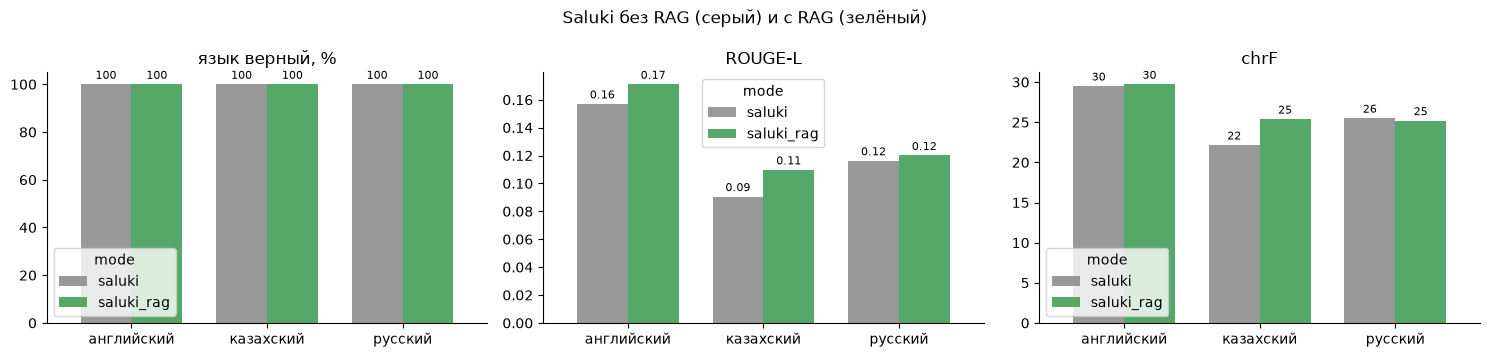

In [6]:
plot_metrics = [m for m in ("язык верный", "ROUGE-L", "chrF") if m in df]
by_lang = df.groupby(["lang", "mode"])[plot_metrics].mean().unstack("mode")
by_lang.index = [LANG_NAMES[l] for l in by_lang.index]
display(by_lang.round(3))

fig, axes = plt.subplots(1, len(plot_metrics), figsize=(5 * len(plot_metrics), 3.6))
for ax, m in zip(axes, plot_metrics):
    data = by_lang[m][list(MODES)] * (100 if m == "язык верный" else 1)
    data.plot.bar(ax=ax, rot=0, color=["#999999", "#55A868"], width=0.75)
    ax.set_title(m + (", %" if m == "язык верный" else ""))
    ax.spines[["top", "right"]].set_visible(False)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.0f" if m in ("язык верный", "chrF") else "%.2f", fontsize=8, padding=2)
plt.suptitle("Saluki без RAG (серый) и с RAG (зелёный)")
plt.tight_layout()
plt.show()

## 7. Когда RAG помогает

Для вопросов validation: на скольких RAG ближе к эталону, и зависит ли это от того, насколько хорошую
справку нашёл поиск (ROUGE-L справки к эталону).

,вопросов
с RAG ближе к эталону,37
примерно одинаково (±0.01),7
без RAG ближе к эталону,16


Прирост от RAG в зависимости от качества найденной справки:


,вопросов,прирост ROUGE-L от RAG
слабая справка (<0.1),9,0.016
средняя (0.1–0.2),22,-0.002
хорошая (>0.2),29,0.022


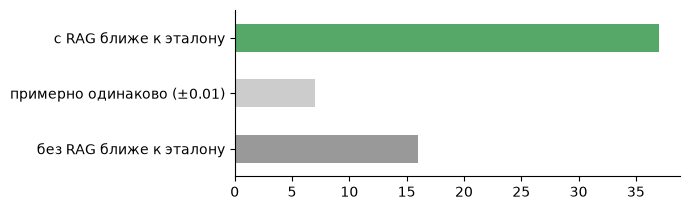

In [7]:
wide = df[df["source"] == "validation"].pivot(index="id", columns="mode", values="ROUGE-L").dropna()
diff = wide["saluki_rag"] - wide["saluki"]
wins = pd.Series({"с RAG ближе к эталону": int((diff > 0.01).sum()),
                  "примерно одинаково (±0.01)": int((diff.abs() <= 0.01).sum()),
                  "без RAG ближе к эталону": int((diff < -0.01).sum())})
display(wins.to_frame("вопросов"))

quality = pd.Series({q["id"]: q["context_rouge"] for q in questions if q["context_rouge"] is not None})
bins = pd.cut(quality.reindex(diff.index), [-0.01, 0.1, 0.2, 1.0], labels=["слабая справка (<0.1)",
                                                                       "средняя (0.1–0.2)", "хорошая (>0.2)"])
effect = pd.DataFrame({"вопросов": diff.groupby(bins, observed=False).size(),
                       "прирост ROUGE-L от RAG": diff.groupby(bins, observed=False).mean().round(3)})
print("Прирост от RAG в зависимости от качества найденной справки:")
display(effect)
ax = wins.plot.barh(color=["#55A868", "#cccccc", "#999999"], figsize=(7, 2.2))
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 8. Срочные вопросы

In [8]:
found = {q["id"]: q["rag_questions"] for q in questions}
for qid in [q["id"] for q in questions if q["urgent"]]:
    pair = df[df["id"] == qid].set_index("mode")
    print(f"===== [{pair.iloc[0]['lang']}] {pair.iloc[0]['question']}")
    print("   RAG нашёл:", " | ".join(found[qid]))
    for mode in MODES:
        if mode in pair.index:
            mark = "✅ советует" if pair.loc[mode, "совет к врачу / 103"] else "❌ НЕ советует"
            print(f"--- {mode} ({mark}):\n{pair.loc[mode, 'answer'][:700]}\n")

===== [en] I have severe chest pain spreading to my left arm. What should I do?
   RAG нашёл: What is Chest Pain? | What is Chest Injuries and Disorders? | What are the symptoms of Pericarditis?
--- saluki (✅ советует):
Severe chest pain radiating to the left arm is a classic symptom of a heart attack, which requires immediate emergency attention. Call your local emergency number (such as 911) or go to the nearest emergency room right away; do not drive yourself if possible. While waiting for help, remain calm and rest in a comfortable position, and take aspirin only if advised by a medical professional and you are not allergic. Do not wait to see if symptoms improve, as prompt treatment is critical for survival.

--- saluki_rag (✅ советует):
Severe chest pain that spreads to the left arm is a classic warning sign of a heart attack and requires immediate emergency attention. Call 911 or your local emergency number right away, and do not drive yourself to the hospital. While waiting for

## 9. Примеры ответов рядом

In [9]:
examples = df[df["source"] == "validation"].drop_duplicates("lang")["id"].tolist()
examples += df[df["source"] == "новые"].drop_duplicates("lang")["id"].tolist()
for qid in examples:
    pair = df[df["id"] == qid].set_index("mode")
    first = pair.iloc[0]
    print(f"================ [{first['lang']}, {first['source']}] {first['question']}")
    print("   RAG нашёл:", " | ".join(found[qid]))
    if isinstance(first["reference"], str):
        print(f"--- эталон:\n{first['reference'][:600]}\n")
    for mode in MODES:
        if mode in pair.index:
            print(f"--- {mode}:\n{pair.loc[mode, 'answer'][:600]}\n")

================ [en, validation] Who is at risk for Lung Cancer??
   RAG нашёл: Who is at risk for Non-Small Cell Lung Cancer?? | How to prevent Lung Cancer? | How many people are affected by lung cancer?
--- эталон:
Risk factors that increase your chance of getting lung cancer include - cigarette, cigar, and pipe smoking, which account for well over half of all cases of lung cancer - secondhand smoke - family history - HIV infection - environmental risk factors - beta carotene supplements in heavy smokers. cigarette, cigar, and pipe smoking, which account for well over half of all cases of lung cancer secondhand smoke family history HIV infection environmental risk factors beta carotene supplements in heavy smokers.

--- saluki:
Lung cancer risk is significantly elevated by smoking, including exposure to secondhand smoke, and occupational inhalation of asbestos, radon gas, or other carcinogens. Additional factors include a family history of lung cancer, prior lung diseases like COPD,

## 10. Таблица для врача (слепая проверка)

Ответы перемешаны: в строке **ответ A** и **ответ B** в случайном порядке, врач не знает, где RAG.

- `results/saluki/doctor_sheet_rag.csv` — отдать врачу; колонки оценки: **верно / частично / неверно / опасно**;
- `results/saluki/doctor_key_rag.csv` — ключ (какая буква какой режим), врачу **не** показывать.

In [10]:
rng = random.Random(SEED)
sheet, key = [], []
for qid, pair in df.groupby("id", sort=False):
    pair = pair.set_index("mode")
    if not set(MODES) <= set(pair.index):
        continue
    order = list(MODES)
    rng.shuffle(order)
    first = pair.iloc[0]
    sheet.append({"id": qid, "язык": first["lang"], "вопрос": first["question"],
                  "эталон (если есть)": first["reference"] if isinstance(first["reference"], str) else "",
                  "ответ A": pair.loc[order[0], "answer"], "оценка A": "",
                  "ответ B": pair.loc[order[1], "answer"], "оценка B": "", "комментарий": ""})
    key.append({"id": qid, "A": order[0], "B": order[1]})
pd.DataFrame(sheet).to_csv(SALUKI_RESULTS / "doctor_sheet_rag.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(key).to_csv(SALUKI_RESULTS / "doctor_key_rag.csv", index=False, encoding="utf-8-sig")
print(f"Для врача: results/saluki/doctor_sheet_rag.csv ({len(sheet)} вопросов); ключ: results/saluki/doctor_key_rag.csv")

Для врача: results/saluki/doctor_sheet_rag.csv (126 вопросов); ключ: results/saluki/doctor_key_rag.csv


## 11. Как понять результат

**RAG помог**, если в режиме saluki_rag:
- выше **ROUGE-L / chrF** и он ближе к эталону на большинстве вопросов validation (раздел 7);
- прирост больше там, где поиск нашёл **хорошую справку** — значит, модель действительно ей пользуется;
- язык ответа не пострадал (справка на том же языке), обрывов и повторов не больше;
- на **срочных** вопросах советует скорую не реже, чем без RAG.

**RAG мешает**, если с ним хуже: например, модель пересказывает нерелевантную справку
(высокая «опора на справку» при слабой справке) или срочные ответы становятся менее чёткими.

Срочные вопросы — особый случай: в MedQuAD нет статей «что делать прямо сейчас», поэтому RAG здесь
находит лишь отдалённо похожие статьи. Для них лучше помогает отдельная база инструкций по неотложным ситуациям.

**Окончательно** — по оценке врача в `doctor_sheet_rag.csv`.